**Domanda Principale**: Come impattano i ritardi di consegna sulla soddisfazione dei clienti di Olist, e come possiamo prevederli in anticipo per proteggere il brand?

In [1]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import sqlite3
import pandas as pd

DATA_DIR = '../data/'

orders = pd.read_csv('../data/olist_orders_dataset.csv')
customers = pd.read_csv('../data/olist_customers_dataset.csv')
payments = pd.read_csv('../data/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../data/olist_order_reviews_dataset.csv')

conn = sqlite3.connect('../data/ecommerce.db')

orders.to_sql('orders', conn, if_exists='replace', index=False)
customers.to_sql('customers', conn, if_exists='replace', index=False)
payments.to_sql('payments', conn, if_exists='replace', index=False)
reviews.to_sql('reviews', conn, if_exists='replace', index=False)

print("Database 'ecommerce.db' creato e tabelle caricate con successo!")

Database 'ecommerce.db' creato e tabelle caricate con successo!


In [3]:
query_1 = """
SELECT
    COUNT(DISTINCT o.order_id) AS totale_ordini,
    COUNT(DISTINCT c.customer_unique_id) AS totale_clienti_reali,
    (1 - (CAST(COUNT(DISTINCT c.customer_unique_id) AS REAL) / COUNT(DISTINCT o.order_id))) * 100 AS tasso_riacquisto
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id;
"""

df_kpi = pd.read_sql_query(query_1, conn)
df_kpi

,totale_ordini,totale_clienti_reali,tasso_riacquisto
0,99441,96096,3.363804


**customer_id** rappresenta l'ID (che si crea) collegato al determinato ordine, mentre **customer_unique_id** rappresenta la persona fisica.

---


99.441 ordini effettuati vs 96.096 clienti unici, tasso di riacquisto uguale al 3.36%.

In [4]:
query_2 = """
SELECT
  c.customer_state AS stato_cliente,
  COUNT(DISTINCT o.order_id) AS numero_ordini,
  COUNT(DISTINCT c.customer_unique_id) AS numero_clienti_reali,
  ROUND(AVG(p.payment_value), 2) AS media_pagamento,
  ROUND(AVG(r.review_score), 2) AS media_votazione

FROM orders o

JOIN customers c ON c.customer_id = o.customer_id
JOIN payments p ON p.order_id = o.order_id
JOIN reviews r ON r.order_id = o.order_id

WHERE o.order_status = 'delivered'

GROUP BY c.customer_state
ORDER BY media_votazione ASC;
"""

df_kpi = pd.read_sql_query(query_2, conn)
df_kpi

,stato_cliente,numero_ordini,numero_clienti_reali,media_pagamento,media_votazione
0,MA,712,695,200.61,3.81
1,AL,394,384,225.57,3.84
2,RR,41,40,220.48,3.90
3,SE,334,328,201.58,3.90
4,PA,933,911,214.23,3.91
5,BA,3229,3132,169.75,3.93
6,CE,1273,1252,198.89,3.95
7,PI,471,460,209.21,3.95
8,RJ,12211,11790,157.25,3.97
9,PB,512,499,250.56,4.07


In [5]:
query_3 = """
SELECT
  o.order_id,
  o.customer_id,
  c.customer_unique_id,
  c.customer_state,
  o.order_purchase_timestamp,
  o.order_approved_at,
  o.order_delivered_carrier_date,
  o.order_delivered_customer_date,
  o.order_estimated_delivery_date,
  SUM(p.payment_value) AS totale_pagamento,
  ROUND(AVG(r.review_score), 2) AS media_votazione

FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
JOIN payments p ON p.order_id = o.order_id
JOIN reviews r ON r.order_id = o.order_id

WHERE o.order_status = 'delivered'

GROUP BY o.order_id;
"""

df_ecommerce = pd.read_sql_query(query_3, conn)
df_ecommerce.head()


,order_id,customer_id,customer_unique_id,customer_state,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,totale_pagamento,media_votazione
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,72.19,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,259.83,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,216.87,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,25.78,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,218.04,5.0


In [6]:
df_ecommerce.to_csv('../data/ecommerce_clean.csv', index=False)

In [7]:
import pandas as pd

df_ecommerce = pd.read_csv('../data/ecommerce_clean.csv')
df_ecommerce.head()

,order_id,customer_id,customer_unique_id,customer_state,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,totale_pagamento,media_votazione
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,72.19,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,259.83,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,216.87,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00,25.78,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00,218.04,5.0


In [8]:
df_ecommerce.info()

<class 'pandas.DataFrame'>
RangeIndex: 95831 entries, 0 to 95830
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       95831 non-null  str    
 1   customer_id                    95831 non-null  str    
 2   customer_unique_id             95831 non-null  str    
 3   customer_state                 95831 non-null  str    
 4   order_purchase_timestamp       95831 non-null  str    
 5   order_approved_at              95817 non-null  str    
 6   order_delivered_carrier_date   95829 non-null  str    
 7   order_delivered_customer_date  95823 non-null  str    
 8   order_estimated_delivery_date  95831 non-null  str    
 9   totale_pagamento               95831 non-null  float64
 10  media_votazione                95831 non-null  float64
dtypes: float64(2), str(9)
memory usage: 25.7 MB


**DATA CLEANING**

In [9]:
df_ecommerce.isnull().sum()

order_id                          0
customer_id                       0
customer_unique_id                0
customer_state                    0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
totale_pagamento                  0
media_votazione                   0
dtype: int64

In [10]:
df_ecommerce = df_ecommerce.dropna(subset=['order_delivered_customer_date'])

# Percentuale dati nulli in base alla lunghezza del dataframe
(df_ecommerce.isnull().sum() / len(df_ecommerce)) * 100

order_id                         0.000000
customer_id                      0.000000
customer_unique_id               0.000000
customer_state                   0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.014610
order_delivered_carrier_date     0.001044
order_delivered_customer_date    0.000000
order_estimated_delivery_date    0.000000
totale_pagamento                 0.000000
media_votazione                  0.000000
dtype: float64

In [11]:
df_ecommerce.duplicated().sum()

np.int64(0)

In [12]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
  df_ecommerce[col] = pd.to_datetime(df_ecommerce[col])
df_ecommerce.info()

<class 'pandas.DataFrame'>
Index: 95823 entries, 0 to 95830
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       95823 non-null  str           
 1   customer_id                    95823 non-null  str           
 2   customer_unique_id             95823 non-null  str           
 3   customer_state                 95823 non-null  str           
 4   order_purchase_timestamp       95823 non-null  datetime64[us]
 5   order_approved_at              95809 non-null  datetime64[us]
 6   order_delivered_carrier_date   95822 non-null  datetime64[us]
 7   order_delivered_customer_date  95823 non-null  datetime64[us]
 8   order_estimated_delivery_date  95823 non-null  datetime64[us]
 9   totale_pagamento               95823 non-null  float64       
 10  media_votazione                95823 non-null  float64       
dtypes: datetime64[us](5), float64(2

In [13]:
anomalie = df_ecommerce[df_ecommerce['order_delivered_customer_date'] < df_ecommerce['order_purchase_timestamp']]
anomalie

,order_id,customer_id,customer_unique_id,customer_state,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,totale_pagamento,media_votazione


In [14]:

df_ecommerce["days_to_delivery"] = (df_ecommerce["order_delivered_customer_date"] - df_ecommerce["order_purchase_timestamp"]).dt.days
df_ecommerce["days_to_delivery"]

0         7
1        16
2         7
3         6
4        25
         ..
95826    17
95827     9
95828     4
95829     1
95830     5
Name: days_to_delivery, Length: 95823, dtype: int64

In [15]:
df_ecommerce.info()

<class 'pandas.DataFrame'>
Index: 95823 entries, 0 to 95830
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       95823 non-null  str           
 1   customer_id                    95823 non-null  str           
 2   customer_unique_id             95823 non-null  str           
 3   customer_state                 95823 non-null  str           
 4   order_purchase_timestamp       95823 non-null  datetime64[us]
 5   order_approved_at              95809 non-null  datetime64[us]
 6   order_delivered_carrier_date   95822 non-null  datetime64[us]
 7   order_delivered_customer_date  95823 non-null  datetime64[us]
 8   order_estimated_delivery_date  95823 non-null  datetime64[us]
 9   totale_pagamento               95823 non-null  float64       
 10  media_votazione                95823 non-null  float64       
 11  days_to_delivery               

In [16]:
df_ecommerce["retard_compared_to_estimate"] = (df_ecommerce["order_delivered_customer_date"] - df_ecommerce["order_estimated_delivery_date"]).dt.days
df_ecommerce["retard_compared_to_estimate"]

0        -9
1        -3
2       -14
3        -6
4       -16
         ..
95826    -8
95827    -9
95828   -13
95829    -9
95830   -14
Name: retard_compared_to_estimate, Length: 95823, dtype: int64

**Interpretazione**: *Giorni di Ritardo Rispetto alla Stima*

---


1.   𝕍𝔸𝕃𝕆ℝ𝔼 > 0: l'ordine è arrivato in *ritardo* di N giorni.
2.   𝕍𝔸𝕃𝕆ℝ𝔼 <= 0: l'ordine è arrivato in *anticipo* o perfettamente in *orario*.

In [17]:
df_ecommerce["retard_compared_to_estimate"].describe()

count    95823.000000
mean       -11.913570
std         10.110605
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: retard_compared_to_estimate, dtype: float64



*   La maggioranza degli ordini arriva con circa 12 giorni di anticipo rispetto alla data promessa al cliente.
*   oltre il 75% degli ordini arriva con almeno una settimana di anticipo.



**Scelta di business**: Olist preferisce promettere date molto lontane per fare in modo che il cliente sia felicemente sorpreso dal riceverlo prima.

In [18]:
df_ecommerce["is_delayed"] = (df_ecommerce["retard_compared_to_estimate"] > 0).astype(int)

df_ecommerce["is_delayed"].value_counts(normalize=True) * 100

is_delayed
0    93.341891
1     6.658109
Name: proportion, dtype: float64

In [19]:
df_ecommerce.groupby("is_delayed")["media_votazione"].mean()

is_delayed
0    4.290589
1    2.272022
Name: media_votazione, dtype: float64

In [20]:
df_ecommerce.groupby("is_delayed")["media_votazione"].count()

is_delayed
0    89443
1     6380
Name: media_votazione, dtype: int64

In [21]:
df_ecommerce.groupby("is_delayed")["media_votazione"].describe()

,count,mean,std,min,25%,50%,75%,max
is_delayed,,,,,,,,
0,89443.0,4.290589,1.147940,1.0,4.0,5.0,5.0,5.0
1,6380.0,2.272022,1.571101,1.0,1.0,1.0,4.0,5.0




*   **Media globale** votazione di Olist: 4.16 stelle (mediana 5.0)
*   **Ordini in Orario** (93.34%): 4.29 stelle di media
*   **Ordini in Ritardo** (6.66%): 2.27 stelle di media


---
Quindi quei 6.66% producono un abbassamento di votazione media globale di **-0.13** stelle.

Il che è apparentemente contenuto, ma se pensiamo alla Customer Satisfaction ossia a livello micro, la votazione passa da 4.29 a 2.27. E si parla di **6380 clienti**.






Bisogna intercettare in anticipo quel 6.66% di ordini ad alto rischio.

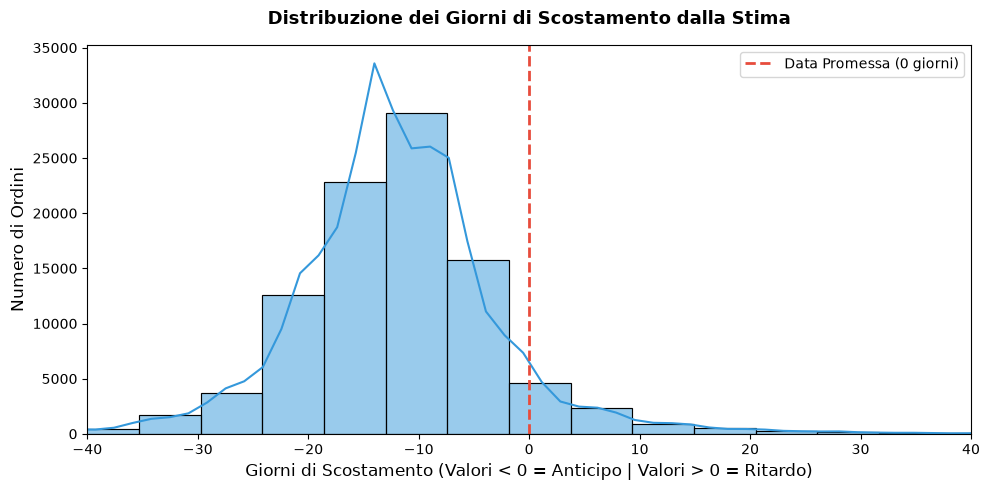

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Istogramma con curva di densità
sns.histplot(
    data=df_ecommerce,
    x="retard_compared_to_estimate",
    bins=60,
    kde=True,
    color="#3498db",
)

plt.axvline(
    0,
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    label="Data Promessa (0 giorni)",
)

plt.title(
    "Distribuzione dei Giorni di Scostamento dalla Stima",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.xlabel(
    "Giorni di Scostamento (Valori < 0 = Anticipo | Valori > 0 = Ritardo)",
    fontsize=12,
)
plt.ylabel("Numero di Ordini", fontsize=12)

plt.xlim(-40, 40)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [23]:
ritardi_per_stato = (df_ecommerce.groupby("customer_state")["is_delayed"].agg(totale_ordini = "count", pct_ritardi = lambda x : x.mean() * 100).reset_index())

ritardi_per_stato = ritardi_per_stato.sort_values(by="pct_ritardi", ascending=False)
ritardi_per_stato


,customer_state,totale_ordini,pct_ritardi
1,AL,394,20.812183
9,MA,712,17.134831
24,SE,334,14.970060
16,PI,471,13.800425
5,CE,1273,13.668500
21,RR,41,12.195122
18,RJ,12211,11.923675
4,BA,3229,11.892227
13,PA,933,10.718114
7,ES,1969,10.411376


C:\Users\yassi\AppData\Local\Temp\ipykernel_38920\775508978.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


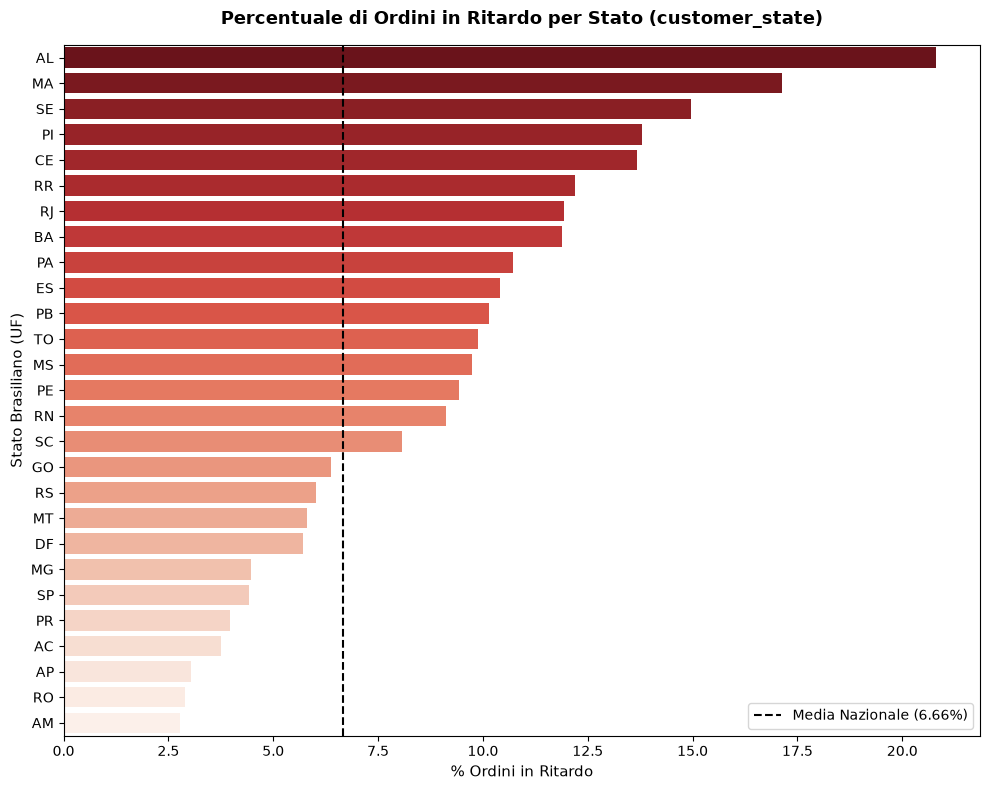

In [24]:
plt.figure(figsize=(10, 8))

ax = sns.barplot(
    data=ritardi_per_stato,
    x="pct_ritardi",
    y="customer_state",
    palette="Reds_r",
)

# Linea di riferimento della media nazionale (6.66%)
media_nazionale = df_ecommerce["is_delayed"].mean() * 100
plt.axvline(
    media_nazionale,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Media Nazionale ({media_nazionale:.2f}%)",
)

plt.title(
    "Percentuale di Ordini in Ritardo per Stato (customer_state)",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.xlabel("% Ordini in Ritardo", fontsize=11)
plt.ylabel("Stato Brasiliano (UF)", fontsize=11)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

**MACHINE LEARNING**

In [25]:
stima_giorni_consegna = (df_ecommerce["order_estimated_delivery_date"] - df_ecommerce["order_purchase_timestamp"]).dt.days
stima_giorni_consegna

0        15
1        18
2        21
3        11
4        40
         ..
95826    24
95827    17
95828    17
95829    10
95830    18
Length: 95823, dtype: int64

In [26]:
mese_acquisto = df_ecommerce["order_purchase_timestamp"].dt.month
mese_acquisto

0         9
1         4
2         1
3         8
4         2
         ..
95826     4
95827     7
95828    10
95829     8
95830     6
Name: order_purchase_timestamp, Length: 95823, dtype: int32

In [27]:
giorno_settimana = df_ecommerce["order_purchase_timestamp"].dt.dayofweek
giorno_settimana

C:\Users\yassi\AppData\Local\Temp\ipykernel_38920\2325350551.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  giorno_settimana = df_ecommerce["order_purchase_timestamp"].dt.dayofweek


0        2
1        2
2        6
3        2
4        5
        ..
95826    0
95827    5
95828    0
95829    0
95830    5
Name: order_purchase_timestamp, Length: 95823, dtype: int32

Encoding di customer_state (**One-Hot Encoding**)

In [28]:
df_ecommerce["stima_giorni_consegna"] = stima_giorni_consegna
df_ecommerce["mese_acquisto"] = mese_acquisto
df_ecommerce["giorno_settimana"] = giorno_settimana

df_ml = pd.get_dummies(
    df_ecommerce[
        [
            "customer_state",
            "totale_pagamento",
            "stima_giorni_consegna",
            "mese_acquisto",
            "giorno_settimana",
            "is_delayed",
        ]
    ],
    columns=["customer_state"],
    drop_first=True,
)

df_ml.head()

,totale_pagamento,stima_giorni_consegna,mese_acquisto,giorno_settimana,is_delayed,customer_state_AL,customer_state_AM,customer_state_AP,customer_state_BA,customer_state_CE,...,customer_state_PR,customer_state_RJ,customer_state_RN,customer_state_RO,customer_state_RR,customer_state_RS,customer_state_SC,customer_state_SE,customer_state_SP,customer_state_TO
0,72.19,15,9,2,0,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
1,259.83,18,4,2,0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,216.87,21,1,6,0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,25.78,11,8,2,0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,218.04,40,2,5,0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


In [29]:
X = df_ml.drop(columns=["is_delayed"])
y = df_ml["is_delayed"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_lr = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=42
)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)
y_pred_proba_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_lr))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_lr))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")

=== Confusion Matrix ===
[[11733  6156]
 [  493   783]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.96      0.66      0.78     17889
           1       0.11      0.61      0.19      1276

    accuracy                           0.65     19165
   macro avg       0.54      0.63      0.48     19165
weighted avg       0.90      0.65      0.74     19165

ROC-AUC Score: 0.6794


*   Sugli ordini effettivamente arrivati in ritardo nel test set, il modello ne ha itercettati il **61%** (**recall**).  
*   Bisogna usare un modello diverso, anche perchè il **precision** è al **11%**, creando **6156 falsi positivi** per raggiungere la recall del 61%.





In [31]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_estimators=100,
    n_jobs=-1,
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
y_pred_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_rf))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_rf))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")


=== Confusion Matrix ===
[[16803  1086]
 [ 1008   268]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.94      0.94      0.94     17889
           1       0.20      0.21      0.20      1276

    accuracy                           0.89     19165
   macro avg       0.57      0.57      0.57     19165
weighted avg       0.89      0.89      0.89     19165

ROC-AUC Score: 0.7134


Seppur migliore del logistic regression in quasi tutto vi è il 9% di recall su 1, facendosi sfuggire il 91% di ritardi reali.

Qi default, Scikit-Learn assegna la classe 1 solo se la probabilità calcolata dal modello supera il $50\%$ ($0.50$). Abbassiamola a 15%.

In [32]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Impostiamo una soglia di decisione del 15% (0.15)
soglia = 0.15
y_pred_soglia = (y_pred_proba_rf >= soglia).astype(int)

print(f"=== CLASSIFICATION REPORT (Soglia = {soglia}) ===")
print(classification_report(y_test, y_pred_soglia))

print("=== MATRICE DI CONFUSIONE ===")
print(confusion_matrix(y_test, y_pred_soglia))


=== CLASSIFICATION REPORT (Soglia = 0.15) ===
              precision    recall  f1-score   support

           0       0.96      0.75      0.84     17889
           1       0.14      0.57      0.22      1276

    accuracy                           0.74     19165
   macro avg       0.55      0.66      0.53     19165
weighted avg       0.91      0.74      0.80     19165

=== MATRICE DI CONFUSIONE ===
[[13402  4487]
 [  552   724]]


Già i risultati sono migliori. Ma proviamo a vedere se migliorano con XGBoost.

In [33]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Calcolo del bilanciamento delle classi (6.66% ritardi) e inizializzazione
ratio = (y_train == 0).sum() / (y_train == 1).sum()
model_xgb = XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric="logloss", n_estimators=100)

# 2. Addestramento e Previsione
model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)
y_pred_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

# 3. Valutazione
print("=== MATRICE DI CONFUSIONE (XGBoost) ===")
print(confusion_matrix(y_test, y_pred_xgb))
print("\n=== CLASSIFICATION REPORT (XGBoost) ===")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}")

=== MATRICE DI CONFUSIONE (XGBoost) ===
[[13921  3968]
 [  491   785]]

=== CLASSIFICATION REPORT (XGBoost) ===
              precision    recall  f1-score   support

           0       0.97      0.78      0.86     17889
           1       0.17      0.62      0.26      1276

    accuracy                           0.77     19165
   macro avg       0.57      0.70      0.56     19165
weighted avg       0.91      0.77      0.82     19165

ROC-AUC Score: 0.7601


Qui abbiamo un notevole miglioramento.


*   **Recall** al **62%** nativa (senza dover abbassare alcuna soglia) e f1-score a 0.26.
*   **ROC-AUC** a **0.76**, che dimostra una capacità molto più solida di ordinare gli ordini dal più rischioso al meno rischioso.





C:\Users\yassi\AppData\Local\Temp\ipykernel_38920\258089215.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


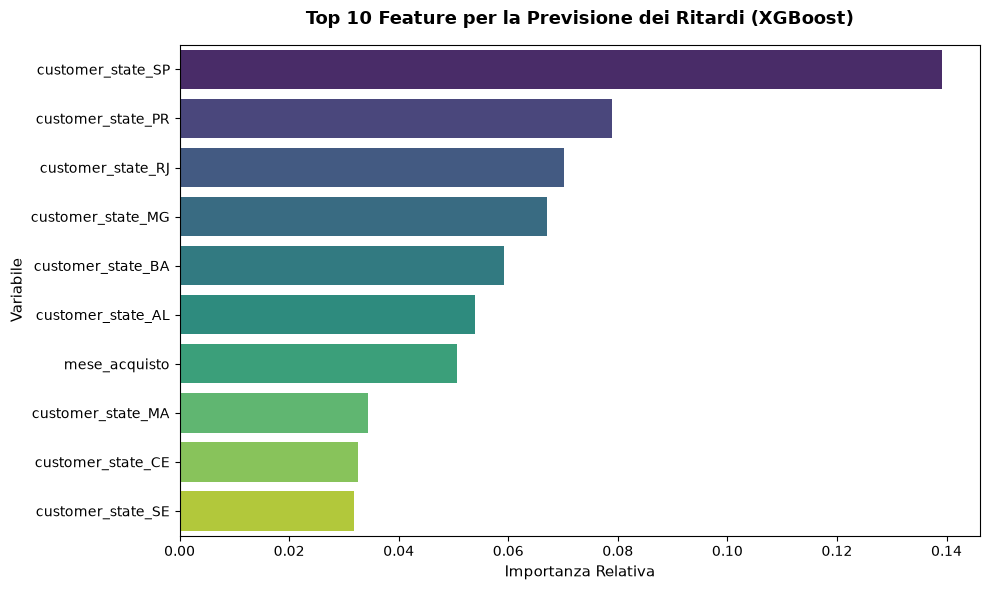

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Estrazione dell'importanza delle variabili da XGBoost
importances = pd.Series(model_xgb.feature_importances_, index=X.columns)
top_10_features = importances.sort_values(ascending=False).head(10)

# 2. Visualizzazione con Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_10_features.values, y=top_10_features.index, palette="viridis"
)

plt.title(
    "Top 10 Feature per la Previsione dei Ritardi (XGBoost)",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.xlabel("Importanza Relativa", fontsize=11)
plt.ylabel("Variabile", fontsize=11)

plt.tight_layout()
plt.show()

###Feature Importance (XGBoost)

L'analisi dell'importanza delle variabili nel modello XGBoost mostra una forte focalizzazione sulla dimensione territoriale:

* **Predominanza della Geografia (`customer_state_*`):** La localizzazione del cliente guida le prime decisioni dell'algoritmo. Lo Stato di San Paolo (**`customer_state_SP`** - ~14%) rappresenta il primo nodo di decisione grazie al volume dominante (oltre il 40% degli ordini), seguito da hub chiave come **PR**, **RJ** e **MG**.
* **Isolamento delle Regioni Critiche:** L'inserimento diretto nella Top 10 di Stati come **AL** (Alagoas), **BA**, **MA**, **CE** e **SE** dimostra come XGBoost individui subito le tratte a più alto tasso di ritardo.
* **Stagionalità (`mese_acquisto`):** Unica variabile non geografica nella Top 10 (~5%), conferma l'impatto dei picchi di vendita distribuiti durante l'anno.


## Conclusioni e Raccomandazioni Strategiche

### 1. Sintesi del Problema e Impatto sul Business
* **Impatto dei Ritardi:** I ritardi di consegna riguardano il **6.66% degli ordini**, ma causano un crollo della valutazione media del cliente da **4.29 a 2.27 stelle** (-47%).
* **Valore del Modello ML:** L'implementazione del modello **XGBoost** consente di identificare al checkout il **62% degli ordini a rischio ritardo** con un **ROC-AUC di 0.7600**, fornendo a Olist uno strumento efficace per la prevenzione proattiva.

### 2. Raccomandazioni Strategiche per Olist
1. **Pre-Alerting sugli Ordini High-Value:** Attivare un sistema di monitoraggio prioritario per ordini ad importo elevato diretti verso aree periferiche o Stati ad alto tasso di ritardo.
2. **Buffer Dinamico Stagionale:** Estendere la data stimata di consegna (`stima_giorni_consegna`) di 2-3 giorni durante i mesi ad alto volume (`mese_acquisto`) per allineare le aspettative del cliente e proteggere il punteggio delle recensioni.


In [35]:
import os
import joblib

# Crea la cartella 'models' nella radice del progetto (risalendo da 'notebooks/')
os.makedirs("../models", exist_ok=True)

# Organizza il dizionario con modello e colonne usate per il training
model_data = {"model": model_xgb, "features": list(X_train.columns)}

# Salva il file esportato
joblib.dump(model_data, "../models/xgb_model.joblib")
print("Modello esportato con successo in 'models/xgb_model.joblib'!")

Modello esportato con successo in 'models/xgb_model.joblib'!
